# Odor Prediction: Morgan Fingerprints vs. GIN-GNN

Predicts multi-label odor descriptors for molecules from the **pyrfume-data** repo
(Leffingwell and GoodScents datasets).

**Pipeline**
1. Setup & data loading 
2. Baselines: Morgan count fingerprints + Random Forest / Logistic Regression 
3. GIN graph model 
4. GNN training with early stopping on validation macro AUROC 
5. Aggregate comparison + per-label scatter plot 
6. Extras: UMAP of embeddings, label-geometry check, atom saliency 


In [245]:
# Configuration (replaces argparse)
SOURCE   = "leffingwell"   # "leffingwell" | "goodscents" | "merged"
SPLIT    = "random"        # "random" | "scaffold"
SEED     = 10
MIN_POS  = 30              # drop labels with fewer positives than this

# GNN hyper-parameters
EPOCHS, PATIENCE = 100, 15
HIDDEN, LAYERS, DROPOUT = 128, 4, 0.2
LR, BATCH_SIZE = 1e-3, 64

DATA_DIR = "./pyrfume-data"
DEVICE   = None 

## 1. Setup

Clone the pyrfume-data repository if it isn't already next to this notebook, and create output folders.

In [246]:
from pathlib import Path

for pkg in ("numpy", "pandas", "rdkit", "sklearn", "torch", "torch_geometric", "matplotlib", "umap"):
    try:
        __import__(pkg)
    except ImportError as e:
        print(f"MISSING: {e}")

data_dir = Path(DATA_DIR)
if not (data_dir / "leffingwell").exists():
    !git clone --depth 1 https://github.com/pyrfume/pyrfume-data {data_dir}

RESULTS, MODELS, FIGS = Path("results"), Path("models"), Path("figures")
for d in (RESULTS, MODELS, FIGS):
    d.mkdir(exist_ok=True)
print("data:", data_dir.resolve())


data: /home/vltp/odor-project/pyrfume-data


## 2. Shared utilities 

Data loading, canonicalization, splits, Morgan fingerprints and per-label AUROC.

In [247]:
import numpy as np
import pandas as pd
from rdkit import Chem, RDLogger
from rdkit.Chem import rdFingerprintGenerator
from rdkit.Chem.Scaffolds import MurckoScaffold
from sklearn.metrics import roc_auc_score

RDLogger.DisableLog("rdApp.*")


def _flat_canonical(smi):
    if not isinstance(smi, str):
        return None
    m = Chem.MolFromSmiles(smi)
    if m is None:
        return None
    Chem.RemoveStereochemistry(m)
    return Chem.MolToSmiles(m)


def _load_leffingwell(d: Path) -> pd.DataFrame:
    st = pd.read_csv(d / "leffingwell" / "stimuli.csv").drop_duplicates("Stimulus").set_index("Stimulus")
    beh = pd.read_csv(d / "leffingwell" / "behavior.csv", index_col=0)
    out = beh.copy()
    out.insert(0, "smiles", st["IsomericSMILES"].reindex(beh.index))
    return out


def _load_goodscents(d: Path) -> pd.DataFrame:
    st = pd.read_csv(d / "goodscents" / "stimuli.csv").drop_duplicates("Stimulus").set_index("Stimulus")
    mol = pd.read_csv(d / "goodscents" / "molecules.csv").drop_duplicates("CID").set_index("CID")
    beh = pd.read_csv(d / "goodscents" / "behavior.csv", index_col=0).dropna(subset=["Descriptors"])
    words = beh["Descriptors"].str.replace(r"\s*;\s*", ";", regex=True).str.strip()
    out = words.str.get_dummies(sep=";")
    out.insert(0, "smiles", st["CID"].map(mol["IsomericSMILES"]).reindex(out.index))
    return out


def load_data(data_dir: Path, source: str = "leffingwell", min_pos: int = 30):
    frames = []
    if source in ("leffingwell", "merged"):
        frames.append(_load_leffingwell(data_dir))
    if source in ("goodscents", "merged"):
        frames.append(_load_goodscents(data_dir))
    df = pd.concat(frames, ignore_index=True)

    df["smiles"] = df["smiles"].map(_flat_canonical)
    df = df.dropna(subset=["smiles"])
    label_cols = [c for c in df.columns if c != "smiles"]
    df[label_cols] = df[label_cols].fillna(0)
    df = df.copy()
    df = df.groupby("smiles", as_index=False)[label_cols].max()

    keep = [c for c in label_cols if df[c].sum() >= min_pos]
    df = df[df[keep].sum(axis=1) > 0].reset_index(drop=True)
    mols = [Chem.MolFromSmiles(s) for s in df["smiles"]]
    return df["smiles"].tolist(), mols, df[keep].values.astype(np.float32), keep


def _scaffold(smi: str) -> str:
    try:
        return MurckoScaffold.MurckoScaffoldSmiles(smiles=smi)
    except Exception:
        return ""


def get_splits(smiles, kind="random", seed=0, test_frac=0.2, val_frac=0.1):
    n = len(smiles)
    rng = np.random.RandomState(seed)
    n_te, n_va = int(n * test_frac), int(n * val_frac)
    if kind == "random":
        idx = rng.permutation(n)
        return idx[n_te + n_va:], idx[n_te:n_te + n_va], idx[:n_te]

    groups = {}
    for i, s in enumerate(smiles):
        sc = _scaffold(s)
        groups.setdefault(sc if sc else f"acyclic_{i}", []).append(i)
    keys = list(groups)
    rng.shuffle(keys)
    te, va, tr = [], [], []
    for k in keys:
        if len(te) < n_te:
            te += groups[k]
        elif len(va) < n_va:
            va += groups[k]
        else:
            tr += groups[k]
    return np.array(tr), np.array(va), np.array(te)


def morgan_counts(mols, radius=2, n_bits=2048) -> np.ndarray:
    gen = rdFingerprintGenerator.GetMorganGenerator(radius=radius, fpSize=n_bits)
    return np.stack([gen.GetCountFingerprintAsNumPy(m) for m in mols]).astype(np.float32)


def per_label_auc(Y_true, Y_score, labels) -> pd.Series:
    out = {}
    for j, name in enumerate(labels):
        y = Y_true[:, j]
        out[name] = np.nan if y.min() == y.max() else roc_auc_score(y, Y_score[:, j])
    return pd.Series(out, name="auc")


def result_path(model: str) -> Path:
    return RESULTS / f"{model}_{SOURCE}_{SPLIT}_seed{SEED}.csv"


## 3. Load data and split

In [248]:
smiles, mols, Y, labels = load_data(data_dir, SOURCE, MIN_POS)
tr, va, te = get_splits(smiles, SPLIT, SEED)
print(f"{len(smiles)} molecules, {len(labels)} labels | train {len(tr)} val {len(va)} test {len(te)}")
print(f"labels: {', '.join(labels[:10])}{' ...' if len(labels) > 10 else ''}")


3384 molecules, 84 labels | train 2370 val 338 test 676
labels: alcoholic, alliaceous, almond, animal, anisic, apple, apricot, aromatic, balsamic, banana ...


## 3b. Exploratory data analysis

Quick look at the labels, the molecules and the data quality **before** modelling.
Uses the variables from section 3 (`smiles`, `mols`, `Y`, `labels`, `tr`, `va`, `te`).

84 labels | positives per label: min 30, median 78, max 1354
most common: fruity (1354), green (867), sweet (807), floral (543), herbal (394), fatty (387), sulfurous (251), waxy (237)
rarest     : medicinal (36), tea (34), apricot (32), ripe (31), hazelnut (31), pine (31), brandy (30), ketonic (30)
labels with prevalence < 5%: 63 / 84


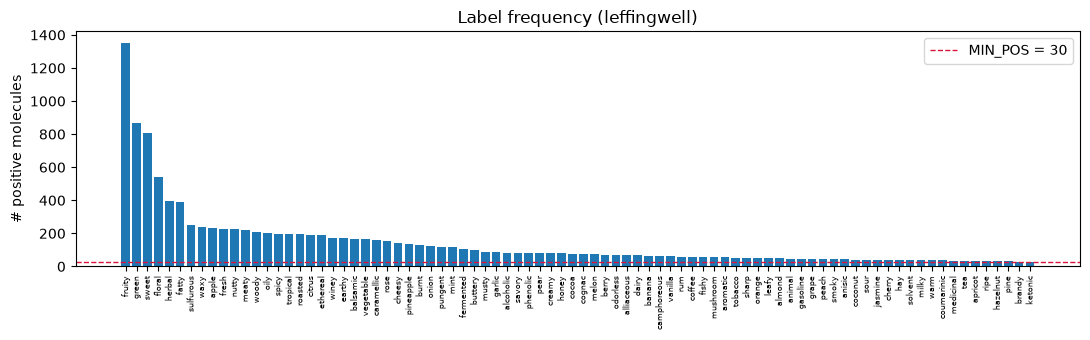

In [249]:

import matplotlib.pyplot as plt
from collections import Counter

counts = pd.Series(Y.sum(0), index=labels).sort_values(ascending=False)
prev = counts / len(Y)
print(f"{len(labels)} labels | positives per label: min {counts.min():.0f}, "
      f"median {counts.median():.0f}, max {counts.max():.0f}")
print("most common:", ", ".join(f"{k} ({int(v)})" for k, v in counts.head(8).items()))
print("rarest     :", ", ".join(f"{k} ({int(v)})" for k, v in counts.tail(8).items()))
print(f"labels with prevalence < 5%: {(prev < 0.05).sum()} / {len(labels)}")

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.bar(range(len(counts)), counts.values)
ax.axhline(MIN_POS, color="crimson", ls="--", lw=1, label=f"MIN_POS = {MIN_POS}")
ax.set_xticks(range(len(counts)))
ax.set_xticklabels(counts.index, rotation=90, fontsize=6)
ax.set_ylabel("# positive molecules")
ax.set_title(f"Label frequency ({SOURCE})")
ax.legend()
fig.tight_layout()
fig.savefig(FIGS / f"eda_label_freq_{SOURCE}.png", dpi=150)
plt.show()

labels per molecule: mean 3.51, median 3, min 1, max 9
molecules with a single label: 9.9%
labels with <5 positives in val: 25 ['alliaceous', 'almond', 'anisic', 'apricot', 'aromatic', 'brandy', 'camphoreous', 'cherry', 'cocoa', 'coconut'] ...
labels with <5 positives in test: 3 ['brandy', 'medicinal', 'tea']
(per-label AUROC on such labels is very noisy; interpret with care)


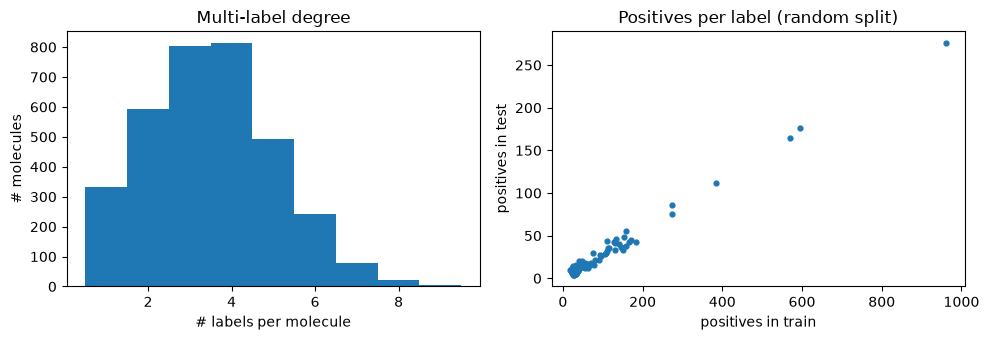

In [250]:

npm = Y.sum(1)
print(f"labels per molecule: mean {npm.mean():.2f}, median {np.median(npm):.0f}, "
      f"min {npm.min():.0f}, max {npm.max():.0f}")
print(f"molecules with a single label: {(npm == 1).mean():.1%}")

split_pos = pd.DataFrame({"train": Y[tr].sum(0), "val": Y[va].sum(0), "test": Y[te].sum(0)}, index=labels)
for s in ("val", "test"):
    thin = split_pos.index[split_pos[s] < 5].tolist()
    print(f"labels with <5 positives in {s}: {len(thin)} {thin[:10]}{' ...' if len(thin) > 10 else ''}")
print("(per-label AUROC on such labels is very noisy; interpret with care)")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(npm, bins=range(1, int(npm.max()) + 2), align="left")
axes[0].set_xlabel("# labels per molecule"); axes[0].set_ylabel("# molecules")
axes[0].set_title("Multi-label degree")
axes[1].scatter(split_pos["train"], split_pos["test"], s=12)
axes[1].set_xlabel("positives in train"); axes[1].set_ylabel("positives in test")
axes[1].set_title(f"Positives per label ({SPLIT} split)")
fig.tight_layout()
fig.savefig(FIGS / f"eda_labels_per_mol_{SOURCE}_{SPLIT}.png", dpi=150)
plt.show()

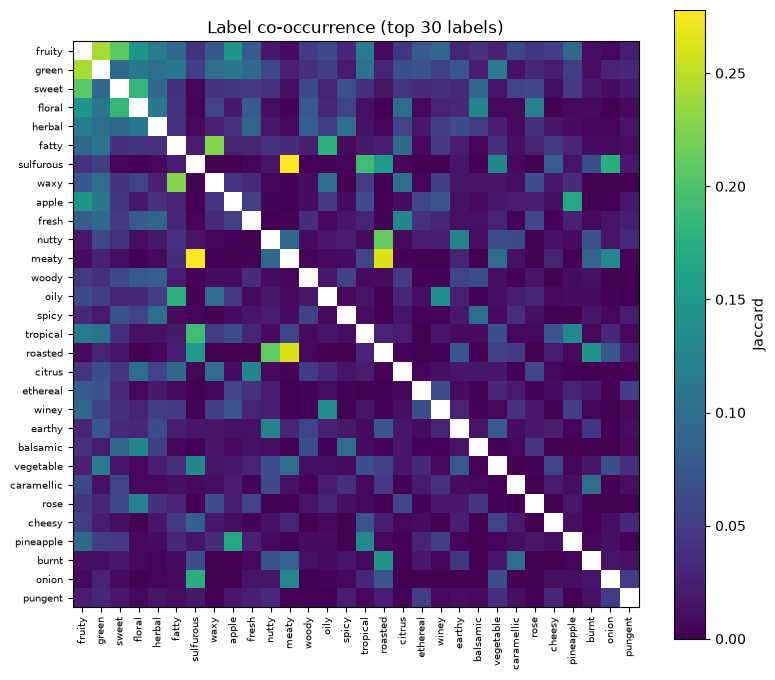

most co-occurring pairs: sulfurous+meaty (0.28), meaty+roasted (0.26), fruity+green (0.24), fatty+waxy (0.23), nutty+roasted (0.21), fruity+sweet (0.21), sulfurous+tropical (0.19), sweet+floral (0.18)


In [251]:

top = list(counts.index[:30])
idx = [labels.index(n) for n in top]
Ys = Y[:, idx]
inter = Ys.T @ Ys
union = Ys.sum(0)[:, None] + Ys.sum(0)[None, :] - inter
jac_top = inter / union
np.fill_diagonal(jac_top, np.nan)

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(jac_top, cmap="viridis")
ax.set_xticks(range(len(top))); ax.set_xticklabels(top, rotation=90, fontsize=7)
ax.set_yticks(range(len(top))); ax.set_yticklabels(top, fontsize=7)
fig.colorbar(im, ax=ax, label="Jaccard")
ax.set_title("Label co-occurrence (top 30 labels)")
fig.tight_layout()
fig.savefig(FIGS / f"eda_cooccurrence_{SOURCE}.png", dpi=150)
plt.show()

iu_t = np.triu_indices(len(top), 1)
order = np.argsort(-np.nan_to_num(jac_top[iu_t]))[:8]
print("most co-occurring pairs:",
      ", ".join(f"{top[iu_t[0][k]]}+{top[iu_t[1][k]]} ({jac_top[iu_t][k]:.2f})" for k in order))

heavy atoms: mean 11.8, median 11, range 2-30
mol. weight: mean 169.1, range 31.1-430.6
acyclic: 51.2% | has aromatic ring: 31.9%
multi-component SMILES ('.'): 0
elements (molecules containing): C 3384, O 2924, S 538, N 340
molecules with atoms outside the GNN element list (-> 'other' bucket): 0


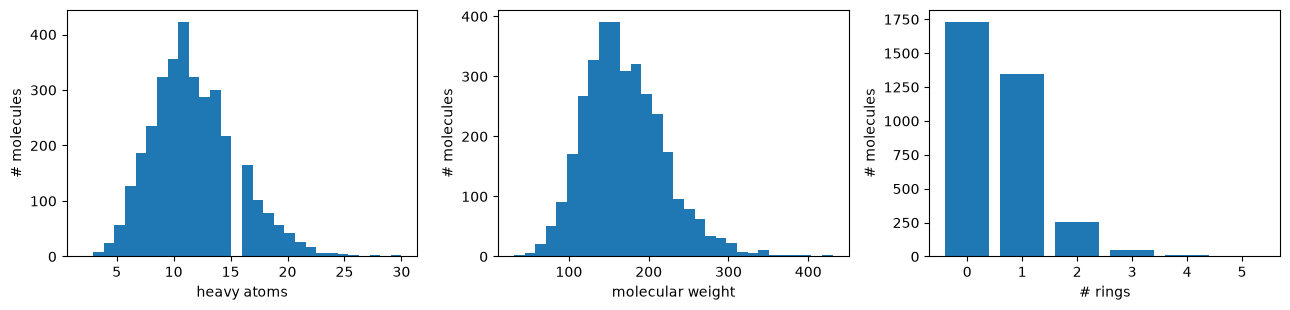

In [252]:

from rdkit.Chem import Descriptors, rdMolDescriptors

heavy = np.array([m.GetNumHeavyAtoms() for m in mols])
mw = np.array([Descriptors.MolWt(m) for m in mols])
n_rings = np.array([rdMolDescriptors.CalcNumRings(m) for m in mols])
has_arom = np.array([rdMolDescriptors.CalcNumAromaticRings(m) > 0 for m in mols])

print(f"heavy atoms: mean {heavy.mean():.1f}, median {np.median(heavy):.0f}, "
      f"range {heavy.min()}-{heavy.max()}")
print(f"mol. weight: mean {mw.mean():.1f}, range {mw.min():.1f}-{mw.max():.1f}")
print(f"acyclic: {(n_rings == 0).mean():.1%} | has aromatic ring: {has_arom.mean():.1%}")
print(f"multi-component SMILES ('.'): {sum('.' in s for s in smiles)}")

# elements (molecules containing each element)
elem = Counter(sym for m in mols for sym in {a.GetSymbol() for a in m.GetAtoms()})
print("elements (molecules containing):", ", ".join(f"{k} {v}" for k, v in elem.most_common()))
known = {"C", "N", "O", "S", "F", "Cl", "Br", "I", "P"}  # same list as the GNN featurizer
n_other = sum(any(a.GetSymbol() not in known for a in m.GetAtoms()) for m in mols)
print(f"molecules with atoms outside the GNN element list (-> 'other' bucket): {n_other}")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
axes[0].hist(heavy, bins=30); axes[0].set_xlabel("heavy atoms")
axes[1].hist(mw, bins=30); axes[1].set_xlabel("molecular weight")
axes[2].bar(*zip(*sorted(Counter(n_rings).items()))); axes[2].set_xlabel("# rings")
for a in axes:
    a.set_ylabel("# molecules")
fig.tight_layout()
fig.savefig(FIGS / f"eda_molecules_{SOURCE}.png", dpi=150)
plt.show()

In [253]:

scaf = [_scaffold(s) for s in smiles]
n_acyc = sum(s == "" for s in scaf)
sc_counts = Counter(s for s in scaf if s)
print(f"acyclic molecules (no scaffold): {n_acyc} ({n_acyc / len(smiles):.1%})")
print(f"unique scaffolds: {len(sc_counts)} over {len(smiles) - n_acyc} cyclic molecules")
print(f"singleton scaffolds: {sum(v == 1 for v in sc_counts.values())}")
biggest = sc_counts.most_common(5)
print("largest scaffold groups:", ", ".join(f"{s} ({n})" for s, n in biggest))
print(f"largest group = {biggest[0][1]} molecules vs test size {len(te)}"
      f" -> {'a single group can fill much of the test set' if biggest[0][1] > 0.25 * len(te) else 'fine for scaffold split'}")

acyclic molecules (no scaffold): 1732 (51.2%)
unique scaffolds: 273 over 1652 cyclic molecules
singleton scaffolds: 167
largest scaffold groups: c1ccccc1 (570), c1ccoc1 (106), C1CCCCC1 (84), C1=CCCCC1 (72), c1cnccn1 (65)
largest group = 570 molecules vs test size 676 -> a single group can fill much of the test set


In [254]:

raw_parts = []
if SOURCE in ("leffingwell", "merged"):
    raw_parts.append(_load_leffingwell(data_dir))
if SOURCE in ("goodscents", "merged"):
    raw_parts.append(_load_goodscents(data_dir))
raw = pd.concat(raw_parts, ignore_index=True)

n_raw = len(raw)
n_no_smiles = int(raw["smiles"].isna().sum())
canon = raw["smiles"].map(_flat_canonical)
n_unparsable = int(canon.isna().sum()) - n_no_smiles
valid = canon.notna()
n_unique = int(canon[valid].nunique())
n_dups = int(valid.sum()) - n_unique

label_cols = [c for c in raw.columns if c != "smiles"]
tmp = raw.assign(smiles=canon).dropna(subset=["smiles"])
tmp[label_cols] = tmp[label_cols].fillna(0)
tmp = tmp.groupby("smiles", as_index=False)[label_cols].max()
keep_cols = [c for c in label_cols if tmp[c].sum() >= MIN_POS]
n_nolabel = int((tmp[keep_cols].sum(axis=1) == 0).sum())

print(f"raw rows:                          {n_raw}")
print(f"  - missing SMILES:                {n_no_smiles}")
print(f"  - unparsable SMILES:             {n_unparsable}")
print(f"  - duplicates merged (after flat canonicalisation): {n_dups}")
print(f"unique molecules:                  {n_unique}")
print(f"labels before / after MIN_POS={MIN_POS}: {len(label_cols)} / {len(keep_cols)}")
print(f"  - molecules dropped (no remaining label): {n_nolabel}")
print(f"final molecules:                   {len(smiles)}")

raw rows:                          3522
  - missing SMILES:                0
  - unparsable SMILES:             0
  - duplicates merged (after flat canonicalisation): 122
unique molecules:                  3400
labels before / after MIN_POS=30: 113 / 84
  - molecules dropped (no remaining label): 16
final molecules:                   3384


/tmp/ipykernel_8066/1565590986.py:19: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  tmp = tmp.groupby("smiles", as_index=False)[label_cols].max()


In [255]:
# --- 7. Source overlap (only meaningful when SOURCE = "merged") ---
if SOURCE != "merged":
    print(f'SOURCE = "{SOURCE}": single source, nothing to compare. Set SOURCE = "merged" to run this check.')
else:
    srcs = {}
    for name, loader in (("leffingwell", _load_leffingwell), ("goodscents", _load_goodscents)):
        d = loader(data_dir)
        d["smiles"] = d["smiles"].map(_flat_canonical)
        d = d.dropna(subset=["smiles"])
        cols = [c for c in d.columns if c != "smiles"]
        d[cols] = d[cols].fillna(0)
        srcs[name] = d.groupby("smiles")[cols].max()
    a, b = srcs["leffingwell"], srcs["goodscents"]
    shared_mols = a.index.intersection(b.index)
    shared_labels = a.columns.intersection(b.columns)
    print(f"leffingwell: {len(a)} mols | goodscents: {len(b)} mols | shared: {len(shared_mols)}")
    print(f"label vocabularies: {a.shape[1]} vs {b.shape[1]} | shared names: {len(shared_labels)}")
    agree = {}
    for lab in shared_labels:
        pa, pb = a.loc[shared_mols, lab] > 0, b.loc[shared_mols, lab] > 0
        u = (pa | pb).sum()
        if u > 0:
            agree[lab] = (pa & pb).sum() / u
    agree = pd.Series(agree).sort_values()
    if len(agree):
        print(f"mean per-label Jaccard agreement on shared molecules: {agree.mean():.2f}")
        print("lowest agreement:", ", ".join(f"{k} {v:.2f}" for k, v in agree.head(5).items()))
        print("highest agreement:", ", ".join(f"{k} {v:.2f}" for k, v in agree.tail(5).items()))

SOURCE = "leffingwell": single source, nothing to compare. Set SOURCE = "merged" to run this check.


## 4. Baselines 

Morgan count fingerprints with **Random Forest** and **Logistic Regression** (one LR per label).

In [256]:
from joblib import Parallel, delayed
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression


def rf_scores(X_tr, Y_tr, X_te, seed):
    rf = RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=seed,
                                class_weight="balanced_subsample")
    rf.fit(X_tr, Y_tr)
    out = np.zeros((len(X_te), Y_tr.shape[1]))
    for j, p in enumerate(rf.predict_proba(X_te)):
        out[:, j] = p[:, 1] if p.shape[1] == 2 else 0.0  # single-class train -> one column
    return out


def _lr_one(X_tr, y, X_te):
    if y.min() == y.max():
        return np.full(len(X_te), float(y[0]))
    clf = LogisticRegression(C=0.1, max_iter=2000, class_weight="balanced")
    clf.fit(X_tr, y)
    return clf.predict_proba(X_te)[:, 1]


def lr_scores(X_tr, Y_tr, X_te):
    cols = Parallel(n_jobs=-1)(delayed(_lr_one)(X_tr, Y_tr[:, j], X_te) for j in range(Y_tr.shape[1]))
    return np.stack(cols, axis=1)


In [257]:
X = morgan_counts(mols)

rf_auc = per_label_auc(Y[te], rf_scores(X[tr], Y[tr], X[te], SEED), labels)
rf_auc.to_csv(result_path("rf"), header=True)
print(f"RF  macro AUROC: {rf_auc.mean():.4f}  (labels scored: {rf_auc.notna().sum()})")

Xl = np.log1p(X)  # damp large counts for the linear model
lr_auc = per_label_auc(Y[te], lr_scores(Xl[tr], Y[tr], Xl[te]), labels)
lr_auc.to_csv(result_path("lr"), header=True)
print(f"LR  macro AUROC: {lr_auc.mean():.4f}")

best = rf_auc.sort_values(ascending=False)
print("easiest labels (RF):", ", ".join(f"{k} {v:.2f}" for k, v in best.head(5).items()))
print("hardest labels (RF):", ", ".join(f"{k} {v:.2f}" for k, v in best.tail(5).items()))


RF  macro AUROC: 0.8666  (labels scored: 84)
LR  macro AUROC: 0.8816
easiest labels (RF): medicinal 0.99, smoky 0.99, vanilla 0.98, sulfurous 0.97, ketonic 0.97
hardest labels (RF): hay 0.70, leafy 0.70, grape 0.68, milky 0.68, warm 0.64


## 5. GIN model 

Atom featurization + a GIN with residual connections, sum+mean pooling, and an MLP head.
`embed()` returns the pooled molecule vector (the "principal odor map" space).

In [258]:
import torch
import torch.nn as nn
from torch_geometric.data import Data
from torch_geometric.nn import GINConv, global_add_pool, global_mean_pool

ELEMS = ["C", "N", "O", "S", "F", "Cl", "Br", "I", "P"]
HYB = [Chem.HybridizationType.SP, Chem.HybridizationType.SP2, Chem.HybridizationType.SP3]


def _onehot(x, choices):
    v = [0] * (len(choices) + 1)  # last slot = "other"
    v[choices.index(x) if x in choices else -1] = 1
    return v


def atom_features(a):
    return (_onehot(a.GetSymbol(), ELEMS)
            + _onehot(a.GetDegree(), [1, 2, 3, 4])
            + _onehot(a.GetTotalNumHs(), [0, 1, 2, 3])
            + _onehot(a.GetHybridization(), HYB)
            + [int(a.GetIsAromatic()), int(a.IsInRing()), a.GetFormalCharge()])


ATOM_DIM = len(atom_features(Chem.MolFromSmiles("C").GetAtomWithIdx(0)))


def mol_to_graph(mol, y=None):
    x = torch.tensor([atom_features(a) for a in mol.GetAtoms()], dtype=torch.float)
    edges = [[b.GetBeginAtomIdx(), b.GetEndAtomIdx()] for b in mol.GetBonds()]
    edges += [[j, i] for i, j in edges]  # make undirected
    edge_index = torch.tensor(edges, dtype=torch.long).t().contiguous() if edges else torch.empty((2, 0), dtype=torch.long)
    data = Data(x=x, edge_index=edge_index)
    if y is not None:
        data.y = torch.tensor(y, dtype=torch.float).unsqueeze(0)
    return data


def make_graphs(mols, Y=None):
    return [mol_to_graph(m, None if Y is None else Y[i]) for i, m in enumerate(mols)]


class OdorGNN(nn.Module):
    def __init__(self, in_dim, n_out, hidden=128, n_layers=4, dropout=0.2):
        super().__init__()
        self.inp = nn.Linear(in_dim, hidden)
        self.convs = nn.ModuleList([
            GINConv(nn.Sequential(nn.Linear(hidden, hidden), nn.BatchNorm1d(hidden),
                                  nn.ReLU(), nn.Linear(hidden, hidden)))
            for _ in range(n_layers)])
        self.norms = nn.ModuleList([nn.BatchNorm1d(hidden) for _ in range(n_layers)])
        self.head = nn.Sequential(nn.Linear(2 * hidden, hidden), nn.ReLU(),
                                  nn.Dropout(dropout), nn.Linear(hidden, n_out))

    def embed(self, x, edge_index, batch):
        h = self.inp(x)
        for conv, bn in zip(self.convs, self.norms):
            h = h + torch.relu(bn(conv(h, edge_index)))
        return torch.cat([global_add_pool(h, batch), global_mean_pool(h, batch)], dim=1)

    def forward(self, x, edge_index, batch):
        return self.head(self.embed(x, edge_index, batch))


## 6. Train the GNN 

Trains with BCE (balanced by positive weight), early stopping on **validation macro AUROC**.
The best checkpoint is saved to `models/` along with the split indices.

In [259]:
import copy, random
from torch_geometric.loader import DataLoader

if DEVICE is None:
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

graphs = make_graphs(mols, Y)
pick = lambda idx: [graphs[i] for i in idx]
train_loader = DataLoader(pick(tr), batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(pick(va), batch_size=256)
test_loader  = DataLoader(pick(te), batch_size=256)

model = OdorGNN(ATOM_DIM, len(labels), HIDDEN, LAYERS, DROPOUT).to(DEVICE)
opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
pos = torch.tensor(Y[tr].mean(0)).clamp(min=1e-3)
loss_fn = nn.BCEWithLogitsLoss(pos_weight=((1 - pos) / pos).clamp(max=20).to(DEVICE))
print(f"model on {DEVICE}, {sum(p.numel() for p in model.parameters())/1e3:.0f}k params")


model on cuda, 181k params


In [260]:
def predict(model, loader):
    model.eval()
    out = []
    with torch.no_grad():
        for b in loader:
            b = b.to(DEVICE)
            out.append(torch.sigmoid(model(b.x, b.edge_index, b.batch)).cpu())
    return torch.cat(out).numpy()


best_val, best_state, bad = -1.0, None, 0
for epoch in range(1, EPOCHS + 1):
    model.train()
    total = 0.0
    for b in train_loader:
        b = b.to(DEVICE)
        opt.zero_grad()
        loss = loss_fn(model(b.x, b.edge_index, b.batch), b.y)
        loss.backward()
        opt.step()
        total += loss.item() * b.num_graphs
    val_auc = per_label_auc(Y[va], predict(model, val_loader), labels).mean()
    print(f"epoch {epoch:3d}  loss {total / len(tr):.4f}  val AUROC {val_auc:.4f}")
    if val_auc > best_val:
        best_val, best_state, bad = val_auc, copy.deepcopy(model.state_dict()), 0
    else:
        bad += 1
        if bad >= PATIENCE:
            print(f"early stop (best val {best_val:.4f})")
            break

model.load_state_dict(best_state)
test_auc = per_label_auc(Y[te], predict(model, test_loader), labels)
test_auc.to_csv(result_path("gnn"), header=True)
print(f"GNN test macro AUROC: {test_auc.mean():.4f}  (best val {best_val:.4f})")


epoch   1  loss 1.0211  val AUROC 0.7335
epoch   2  loss 0.7890  val AUROC 0.8086
epoch   3  loss 0.7352  val AUROC 0.8245
epoch   4  loss 0.6834  val AUROC 0.8485
epoch   5  loss 0.6702  val AUROC 0.8586
epoch   6  loss 0.6433  val AUROC 0.8640
epoch   7  loss 0.6490  val AUROC 0.8677
epoch   8  loss 0.6201  val AUROC 0.8584
epoch   9  loss 0.6150  val AUROC 0.8587
epoch  10  loss 0.5865  val AUROC 0.8732
epoch  11  loss 0.5745  val AUROC 0.8721
epoch  12  loss 0.6027  val AUROC 0.8775
epoch  13  loss 0.5893  val AUROC 0.8773
epoch  14  loss 0.5683  val AUROC 0.8827
epoch  15  loss 0.5675  val AUROC 0.8842
epoch  16  loss 0.5474  val AUROC 0.8848
epoch  17  loss 0.5560  val AUROC 0.8860
epoch  18  loss 0.5466  val AUROC 0.8873
epoch  19  loss 0.5443  val AUROC 0.8859
epoch  20  loss 0.5547  val AUROC 0.8871
epoch  21  loss 0.5323  val AUROC 0.8804
epoch  22  loss 0.5514  val AUROC 0.8852
epoch  23  loss 0.5316  val AUROC 0.8868
epoch  24  loss 0.5522  val AUROC 0.8878
epoch  25  loss 

In [261]:
ckpt = {
    "state_dict": best_state,
    "labels": labels,
    "args": {"source": SOURCE, "split": SPLIT, "seed": SEED, "min_pos": MIN_POS,
             "hidden": HIDDEN, "layers": LAYERS, "dropout": DROPOUT},
    "train_idx": tr, "val_idx": va, "test_idx": te,
}
ckpt_path = MODELS / f"gnn_{SOURCE}_{SPLIT}_seed{SEED}.pt"
torch.save(ckpt, ckpt_path)
print("saved", ckpt_path)


saved models/gnn_leffingwell_random_seed10.pt


## 7. Compare models per label 

Aggregate result CSVs across seeds and scatter GNN vs. RF AUROC per label.

  lr   macro AUROC: 0.8799 +/- 0.0053  (n_seeds=11)
  rf   macro AUROC: 0.8678 +/- 0.0062  (n_seeds=11)
  gnn  macro AUROC: 0.8806 +/- 0.0075  (n_seeds=11)
labels where RF beats GNN most: creamy -0.044, musty -0.043, cheesy -0.028, mushroom -0.027
labels where GNN beats RF most: sour +0.066, sharp +0.066, hay +0.067, ripe +0.118


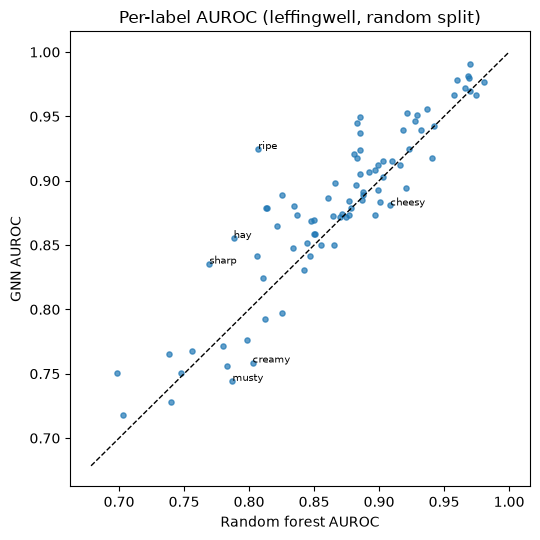

saved figures/gnn_vs_rf_leffingwell_random.png


In [262]:
import matplotlib.pyplot as plt

per_label, macro = {}, {}
for model_name in ("lr", "rf", "gnn"):
    files = sorted(RESULTS.glob(f"{model_name}_{SOURCE}_{SPLIT}_seed*.csv"))
    if not files:
        print(f"skip {model_name}: no result files")
        continue
    df = pd.concat([pd.read_csv(f, index_col=0)["auc"] for f in files], axis=1)
    per_label[model_name] = df.mean(axis=1)
    macro[model_name] = df.mean(axis=0)

for m, s in macro.items():
    print(f"  {m:4s} macro AUROC: {s.mean():.4f} +/- {s.std(ddof=0):.4f}  (n_seeds={len(s)})")

table = pd.DataFrame(per_label)
table.to_csv(RESULTS / f"per_label_{SOURCE}_{SPLIT}.csv")

if {"gnn", "rf"} <= set(table.columns):
    diff = (table["gnn"] - table["rf"]).sort_values()
    print("labels where RF beats GNN most:", ", ".join(f"{k} {v:+.3f}" for k, v in diff.head(4).items()))
    print("labels where GNN beats RF most:", ", ".join(f"{k} {v:+.3f}" for k, v in diff.tail(4).items()))

    fig, ax = plt.subplots(figsize=(5.5, 5.5))
    ax.scatter(table["rf"], table["gnn"], s=14, alpha=0.7)
    lo = float(table[["rf", "gnn"]].min().min()) - 0.02
    ax.plot([lo, 1], [lo, 1], "k--", lw=1)
    for k in list(diff.head(3).index) + list(diff.tail(3).index):
        ax.annotate(k, (table.loc[k, "rf"], table.loc[k, "gnn"]), fontsize=7)
    ax.set_xlabel("Random forest AUROC"); ax.set_ylabel("GNN AUROC")
    ax.set_title(f"Per-label AUROC ({SOURCE}, {SPLIT} split)")
    fig.tight_layout()
    out = FIGS / f"gnn_vs_rf_{SOURCE}_{SPLIT}.png"
    fig.savefig(out, dpi=150)
    plt.show()
    print("saved", out)


## 8. Extras

1. **UMAP** of learned embeddings, one panel per label
2. **Label-geometry check:** does embedding-space cosine similarity between label centroids track label co-occurrence (Jaccard)?
3. **Atom saliency:** grad × input per atom for a label logit — is the top-contributing atom inside the functional group a chemist expects (esters → fruity, sulfur → sulfurous, phenols → phenolic)?

In [263]:
import umap
from rdkit.Chem import Draw
from scipy.stats import spearmanr

EXPECTED_GROUPS = [
    ("fruity", "[CX3](=O)[OX2][#6]"),   # esters
    ("sulfurous", "[#16]"),             # any sulfur
    ("phenolic", "c[OX2H]"),            # phenols
]


In [264]:
def get_embeddings(model, graphs):
    model.eval()
    out = []
    with torch.no_grad():
        for b in DataLoader(graphs, batch_size=256):
            b = b.to(DEVICE)
            out.append(model.embed(b.x, b.edge_index, b.batch).cpu())
    return torch.cat(out).numpy()


def atom_contribution(model, mol, label_idx):
    """grad x input per atom for one label logit; positive = pushes toward the label."""
    g = mol_to_graph(mol).to(DEVICE)
    g.x.requires_grad_(True)
    batch = torch.zeros(g.x.shape[0], dtype=torch.long, device=DEVICE)
    model(g.x, g.edge_index, batch)[0, label_idx].backward()
    return (g.x.grad * g.x).sum(1).detach().cpu().numpy()


model.eval()
E = get_embeddings(model, graphs)
tag = f"{SOURCE}_{SPLIT}_seed{SEED}"
print("embeddings:", E.shape)


embeddings: (3384, 256)


/home/vltp/miniconda3/envs/odor/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


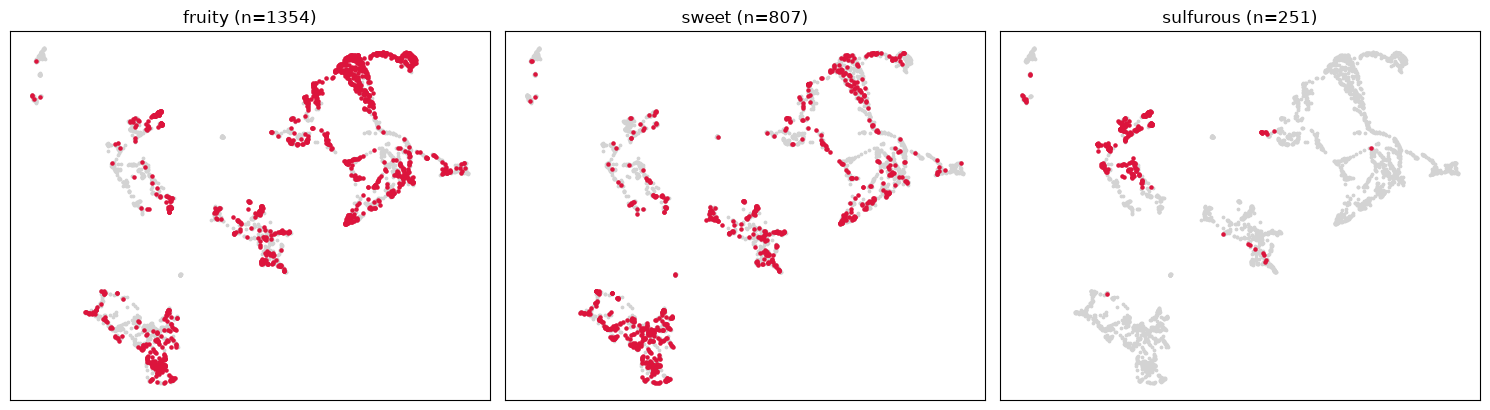

saved figures/umap_leffingwell_random_seed10.png


In [265]:
# ---- 8a. UMAP, one panel per label ----
U = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=0).fit_transform(E)

umap_labels = [n for n in ("fruity", "sweet", "sulfurous") if n in labels]
if len(umap_labels) < 3:  # fall back to the most common labels
    umap_labels = list(np.array(labels)[np.argsort(-Y.sum(0))[:3]])

fig, axes = plt.subplots(1, len(umap_labels), figsize=(5 * len(umap_labels), 4.2))
for ax, name in zip(np.atleast_1d(axes), umap_labels):
    pos = Y[:, labels.index(name)] == 1
    ax.scatter(*U[~pos].T, c="lightgray", s=3)
    ax.scatter(*U[pos].T, c="crimson", s=5)
    ax.set_title(f"{name} (n={pos.sum()})"); ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout()
out = FIGS / f"umap_{tag}.png"
fig.savefig(out, dpi=150)
plt.show()
print("saved", out)
